# NLP Sentiment Classification on Customer Reviews (TF-IDF)

**Task 4 | Natural Language Processing | Scikit-learn**

## Objective
Build a text-classification pipeline that predicts whether a customer review is **positive, negative, or neutral**. The workflow includes dataset loading, text cleaning, TF-IDF feature extraction, model training, evaluation, and an interactive prediction helper.

### Dataset
- Source: [Hugging Face — sentiment-reviews](https://huggingface.co/datasets/davidberg/sentiment-reviews)
- CSV: `EcoPreprocessed.csv`
- Expected columns: `review` (text), `division` (sentiment label), and `polarity` (numeric sentiment score).
- This dataset is already preprocessed to some extent; the notebook still applies consistent text normalization.

> **Note:** The original URL supplied in the task returns 404. This notebook uses a working alternative dataset URL. The code checks the available columns and stops with a clear message if the source schema changes.

### Technical approach
1. Load and inspect the dataset.
2. Clean missing values and duplicate records.
3. Normalize text and optionally lemmatize words with NLTK.
4. Split into training and testing sets.
5. Convert text to TF-IDF vectors (`max_features=5000`, unigrams and bigrams).
6. Train Multinomial Naive Bayes and Logistic Regression.
7. Compare accuracy, precision, recall, F1-score, and confusion matrices.
8. Predict sentiment for custom user-written reviews.
9. Save the best model and TF-IDF vectorizer.

### Libraries
`pandas`, `numpy`, `matplotlib`, `seaborn`, `scikit-learn`, `nltk`, and `joblib`.

## 1. Install and import required libraries

If any library is missing in your Jupyter environment, uncomment and run the installation command below.

In [1]:
# If needed, run this cell once:
# %pip install pandas numpy matplotlib seaborn scikit-learn nltk joblib

import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
from sklearn.pipeline import Pipeline
import joblib

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42
print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load the dataset

The previous GitHub CSV address returned **404 Not Found**. The following Hugging Face CSV is the replacement source.

In [2]:
DATA_URL = (
    "https://huggingface.co/datasets/davidberg/sentiment-reviews/"
    "resolve/main/EcoPreprocessed.csv"
)

df = pd.read_csv(DATA_URL)

print("Dataset loaded successfully.")
print("Rows and columns:", df.shape)
print("\nColumn names:", df.columns.tolist())
display(df.head())

Dataset loaded successfully.
Rows and columns: (4084, 4)

Column names: ['Unnamed: 0', 'review', 'polarity', 'division']


,Unnamed: 0,review,polarity,division
0,3870,able play youtube alexa,0.5000,positive
1,62,able recognize indian accent really well drop ...,0.2794,positive
2,487,absolute smart device amazon connect external ...,0.1827,positive
3,3204,absolutely amaze new member family control hom...,0.3682,positive
4,1265,absolutely amaze previously sceptical invest m...,0.2333,positive


## 3. Explore the dataset

Check data types, missing values, duplicate rows, and the distribution of sentiment labels. In this dataset, `review` is the text and `division` is the class label.

In [3]:
print("Dataset information:")
df.info()

print("\nMissing values by column:")
display(df.isnull().sum().to_frame("missing_values"))

print("\nDuplicate rows:", df.duplicated().sum())

if "division" in df.columns:
    print("\nSentiment label counts:")
    display(df["division"].value_counts(dropna=False).to_frame("count"))
else:
    raise ValueError(
        "Expected target column 'division' was not found. "
        f"Available columns: {df.columns.tolist()}"
    )

if "review" not in df.columns:
    raise ValueError(
        "Expected text column 'review' was not found. "
        f"Available columns: {df.columns.tolist()}"
    )

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 4084 entries, 0 to 4083
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  4084 non-null   int64  
 1   review      4084 non-null   str    
 2   polarity    4084 non-null   float64
 3   division    4084 non-null   str    
dtypes: float64(1), int64(1), str(2)
memory usage: 127.8 KB

Missing values by column:


,missing_values
Unnamed: 0,0
review,0
polarity,0
division,0



Duplicate rows: 0

Sentiment label counts:


,count
division,
positive,3066
neutral,536
negative,482


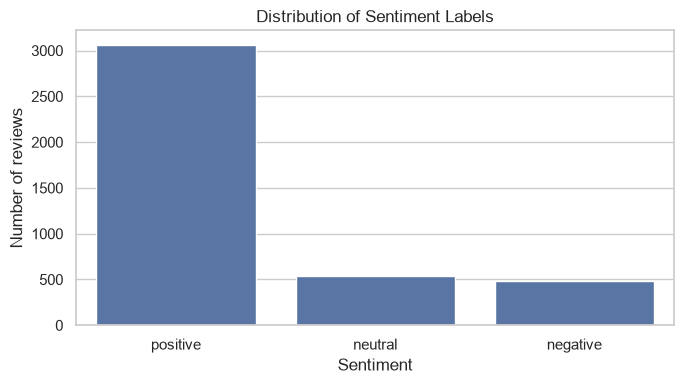

In [4]:
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="division", order=df["division"].value_counts().index)
plt.title("Distribution of Sentiment Labels")
plt.xlabel("Sentiment")
plt.ylabel("Number of reviews")
plt.tight_layout()
plt.show()

## 4. Prepare the text and labels

Keep only the review text and sentiment class. Remove rows with missing text/labels, remove empty reviews, and drop exact duplicate review-label pairs. The `polarity` score is not used as a model input, because the goal is to predict the categorical `division` label from review text.

In [5]:
data = df[["review", "division"]].copy()
data = data.dropna(subset=["review", "division"])
data["review"] = data["review"].astype(str).str.strip()
data["division"] = data["division"].astype(str).str.strip().str.lower()
data = data[data["review"].ne("") & data["division"].ne("")]
data = data.drop_duplicates(subset=["review", "division"]).reset_index(drop=True)

print("Cleaned dataset shape:", data.shape)
print("\nClass labels:", sorted(data["division"].unique()))
display(data.head())

Cleaned dataset shape: (3467, 2)

Class labels: ['negative', 'neutral', 'positive']


,review,division
0,able play youtube alexa,positive
1,able recognize indian accent really well drop ...,positive
2,absolute smart device amazon connect external ...,positive
3,absolutely amaze new member family control hom...,positive
4,absolutely amaze previously sceptical invest m...,positive


## 5. Text preprocessing

The dataset is already described as preprocessed, but this function applies additional normalization: lowercase text, remove URLs/HTML/punctuation, and normalize whitespace. It preserves important negation words such as **not**, **no**, and **never**, because they can reverse sentiment.

Lemmatization is attempted with NLTK's WordNet lemmatizer. If the NLTK resource is unavailable (for example, due to a network restriction), the notebook safely continues using the normalized text.

In [6]:
# Optional NLTK lemmatization setup
lemmatizer = None
try:
    import nltk
    from nltk.stem import WordNetLemmatizer
    try:
        nltk.data.find("corpora/wordnet")
    except LookupError:
        nltk.download("wordnet", quiet=True)
    try:
        nltk.data.find("corpora/omw-1.4")
    except LookupError:
        nltk.download("omw-1.4", quiet=True)

    # Verify the resource is available before using the lemmatizer
    lemmatizer = WordNetLemmatizer()
    lemmatizer.lemmatize("reviews")
    print("NLTK lemmatization is available.")
except Exception as exc:
    lemmatizer = None
    print("NLTK lemmatization unavailable; continuing without it.")
    print("Reason:", str(exc)[:200])

# Build a stopword set while retaining negations and their contractions.
NEGATION_WORDS = {"no", "nor", "not", "never", "n't"}
STOP_WORDS = set(ENGLISH_STOP_WORDS) - NEGATION_WORDS

def preprocess_text(text):
    """Normalize a review while preserving sentiment-relevant negation."""
    text = str(text).lower()
    text = re.sub(r"<[^>]+>", " ", text)          # HTML tags
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)  # URLs
    text = re.sub(r"[^a-z\s']", " ", text)       # punctuation/numbers
    text = re.sub(r"\s+", " ", text).strip()

    tokens = []
    for token in text.split():
        # Keep negation words; remove other common stopwords
        if token in STOP_WORDS:
            continue
        if lemmatizer is not None:
            try:
                token = lemmatizer.lemmatize(token)
            except Exception:
                pass
        tokens.append(token)

    return " ".join(tokens)

data["clean_review"] = data["review"].apply(preprocess_text)
data = data[data["clean_review"].str.strip().ne("")].reset_index(drop=True)

print("Text preprocessing complete.")
display(data[["review", "clean_review", "division"]].head(10))

NLTK lemmatization unavailable; continuing without it.
Reason: No module named 'nltk'
Text preprocessing complete.


,review,clean_review,division
0,able play youtube alexa,able play youtube alexa,positive
1,able recognize indian accent really well drop ...,able recognize indian accent really drop funct...,positive
2,absolute smart device amazon connect external ...,absolute smart device amazon connect external ...,positive
3,absolutely amaze new member family control hom...,absolutely amaze new member family control hom...,positive
4,absolutely amaze previously sceptical invest m...,absolutely amaze previously sceptical invest m...,positive
5,absolutely cheat customer if buy amazon produc...,absolutely cheat customer buy amazon product d...,positive
6,absolutely house hold item fair price intuitiv...,absolutely house hold item fair price intuitiv...,positive
7,absolutely mind blow device beautiful shape ex...,absolutely mind blow device beautiful shape ex...,positive
8,accept dutch language,accept dutch language,neutral
9,accessibility limit amazon apps music appsexce...,accessibility limit amazon apps music appsexce...,negative


## 6. Split into training and testing sets

Use an 80/20 stratified split so the sentiment proportions are approximately preserved in both sets. The test set is held back until evaluation.

In [7]:
X = data["clean_review"]
y = data["division"]

# Stratification requires at least two examples in every class.
class_counts = y.value_counts()
if (class_counts < 2).any():
    raise ValueError(
        "At least one class has fewer than two records; stratified splitting "
        "is not possible. Class counts: " + str(class_counts.to_dict())
    )

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training examples:", len(X_train))
print("Testing examples:", len(X_test))
print("\nTraining label proportions:")
display(y_train.value_counts(normalize=True).rename("proportion").to_frame())

Training examples: 2766
Testing examples: 692

Training label proportions:


,proportion
division,
positive,0.728127
neutral,0.138467
negative,0.133406


## 7. Convert text into TF-IDF features

TF-IDF assigns greater importance to terms that are useful in a document but not common across all documents. Unigrams and bigrams allow the model to learn both individual words and short phrases (for example, “not good”). The vectorizer is fitted only on training data to avoid test-data leakage.

In [8]:
tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2),
    min_df=1,
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF training matrix shape:", X_train_tfidf.shape)
print("TF-IDF testing matrix shape:", X_test_tfidf.shape)
print("Vocabulary size:", len(tfidf.vocabulary_))

TF-IDF training matrix shape: (2766, 5000)
TF-IDF testing matrix shape: (692, 5000)
Vocabulary size: 5000


## 8. Train Multinomial Naive Bayes and Logistic Regression

Both models use the same TF-IDF features and the same train/test split, so their metrics can be compared fairly.

In [9]:
models = {
    "Multinomial Naive Bayes": MultinomialNB(),
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight=None,
        random_state=RANDOM_STATE
    )
}

trained_models = {}
predictions = {}
results = []

for name, model in models.items():
    model.fit(X_train_tfidf, y_train)
    y_pred = model.predict(X_test_tfidf)

    trained_models[name] = model
    predictions[name] = y_pred

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (macro)": precision_score(y_test, y_pred, average="macro", zero_division=0),
        "Recall (macro)": recall_score(y_test, y_pred, average="macro", zero_division=0),
        "F1-score (macro)": f1_score(y_test, y_pred, average="macro", zero_division=0)
    })

results_df = pd.DataFrame(results).sort_values(
    by="F1-score (macro)", ascending=False
).reset_index(drop=True)

display(results_df.style.format({
    "Accuracy": "{:.4f}",
    "Precision (macro)": "{:.4f}",
    "Recall (macro)": "{:.4f}",
    "F1-score (macro)": "{:.4f}"
}))

,Model,Accuracy,Precision (macro),Recall (macro),F1-score (macro)
0,Logistic Regression,0.8006,0.7987,0.5353,0.5875
1,Multinomial Naive Bayes,0.7312,0.5768,0.3406,0.2956


## 9. Compare model performance

Accuracy is the fraction of correct predictions. Macro precision, recall, and F1-score calculate each class equally, which is useful when the classes are not evenly distributed. Use the metrics printed from your run in your final report; do not assume a score before running the notebook.

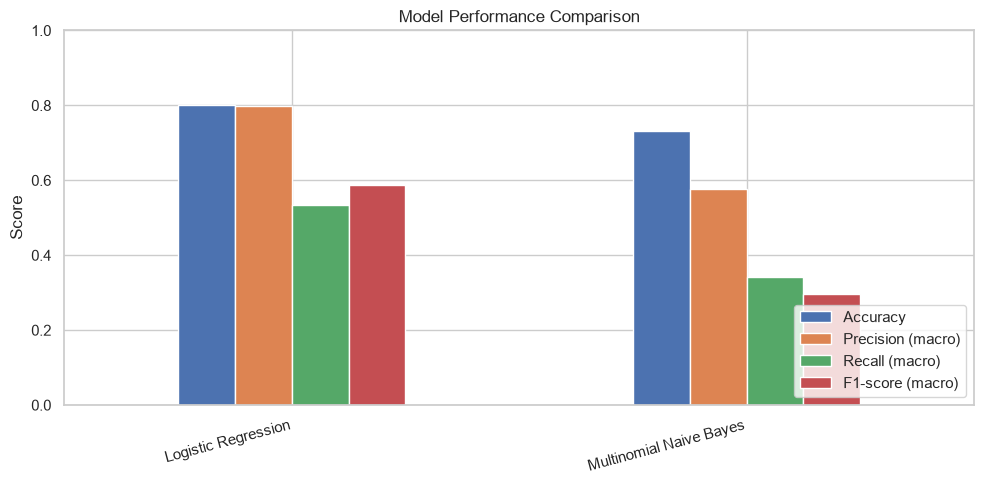

In [10]:
metrics_plot = results_df.set_index("Model")[
    ["Accuracy", "Precision (macro)", "Recall (macro)", "F1-score (macro)"]
]
ax = metrics_plot.plot(kind="bar", figsize=(10, 5), ylim=(0, 1))
ax.set_title("Model Performance Comparison")
ax.set_ylabel("Score")
ax.set_xlabel("")
plt.xticks(rotation=15, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 10. Detailed classification report and confusion matrix

The classification report provides precision, recall, F1-score, and support for each sentiment class. A confusion matrix shows which classes are being mistaken for one another.

Best model by macro F1-score: Logistic Regression

Classification report:
              precision    recall  f1-score   support

    negative       0.87      0.42      0.57        92
     neutral       0.73      0.20      0.31        96
    positive       0.80      0.98      0.88       504

    accuracy                           0.80       692
   macro avg       0.80      0.54      0.59       692
weighted avg       0.80      0.80      0.76       692



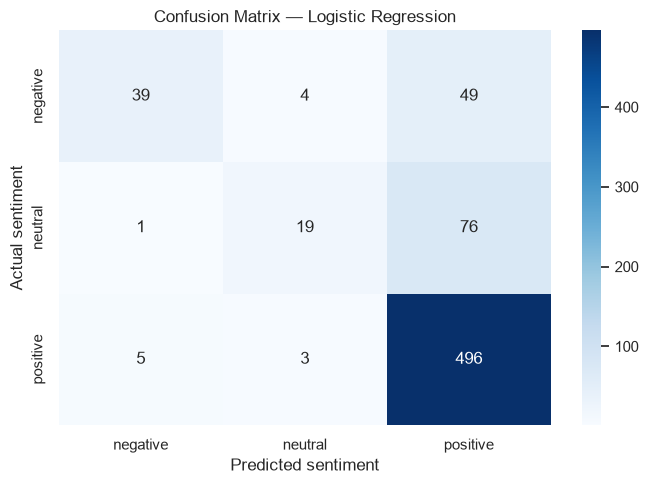

In [11]:
best_model_name = results_df.loc[0, "Model"]
best_model = trained_models[best_model_name]
best_predictions = predictions[best_model_name]

print("Best model by macro F1-score:", best_model_name)
print("\nClassification report:")
print(classification_report(
    y_test,
    best_predictions,
    labels=sorted(y.unique()),
    zero_division=0
))

labels = sorted(y.unique())
cm = confusion_matrix(y_test, best_predictions, labels=labels)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=labels,
    yticklabels=labels
)
plt.title(f"Confusion Matrix — {best_model_name}")
plt.xlabel("Predicted sentiment")
plt.ylabel("Actual sentiment")
plt.tight_layout()
plt.show()

## 11. Interactive custom review predictor

Use `predict_sentiment()` to test a review typed by a user. The text is cleaned and transformed with the **same fitted TF-IDF vectorizer** used for training. If the classifier supports probabilities, the function also returns its class confidence estimates.

> The confidence values are model probabilities, not a guarantee that a prediction is correct.

In [12]:
def predict_sentiment(review_text, show_probabilities=True):
    """Predict positive, negative, or neutral sentiment for a custom review."""
    if not isinstance(review_text, str) or not review_text.strip():
        raise ValueError("Please enter a non-empty review.")

    cleaned = preprocess_text(review_text)
    if not cleaned:
        raise ValueError("The review contains no usable text after preprocessing.")

    features = tfidf.transform([cleaned])
    prediction = best_model.predict(features)[0]

    print("Review:", review_text)
    print("Predicted sentiment:", str(prediction).upper())

    if show_probabilities and hasattr(best_model, "predict_proba"):
        probabilities = best_model.predict_proba(features)[0]
        probability_table = pd.DataFrame({
            "Sentiment": best_model.classes_,
            "Probability": probabilities
        }).sort_values("Probability", ascending=False).reset_index(drop=True)
        display(probability_table.style.format({"Probability": "{:.2%}"}))
        return prediction, probability_table

    return prediction

# Try an example:
predict_sentiment("The product is excellent and works really well!")

Review: The product is excellent and works really well!
Predicted sentiment: POSITIVE


,Sentiment,Probability
0,positive,94.52%
1,neutral,3.37%
2,negative,2.11%


('positive',
   Sentiment  Probability
 0  positive     0.945235
 1   neutral     0.033703
 2  negative     0.021062)

In [13]:
# Try your own review by editing the text below:
my_review = "The product is disappointing and does not work properly."
my_prediction = predict_sentiment(my_review)

Review: The product is disappointing and does not work properly.
Predicted sentiment: NEUTRAL


,Sentiment,Probability
0,neutral,81.27%
1,positive,10.27%
2,negative,8.46%


## 12. Save the trained model and TF-IDF vectorizer

Save both artifacts together with the selected model name and preprocessing function's settings. The Python function itself is defined in this notebook; when reusing the model in another application, copy the `preprocess_text()` function as well.

In [ ]:
MODEL_FILE = "sentiment_classifier.joblib"
VECTORIZER_FILE = "tfidf_vectorizer.joblib"

joblib.dump(best_model, MODEL_FILE)
joblib.dump(tfidf, VECTORIZER_FILE)

print("Saved model to:", MODEL_FILE)
print("Saved vectorizer to:", VECTORIZER_FILE)
print("Selected model:", best_model_name)

Saved model to: sentiment_classifier.joblib
Saved vectorizer to: tfidf_vectorizer.joblib
Selected model: Logistic Regression


## 13. Conclusion and report template

### What this project demonstrates
- Text normalization and basic NLP preprocessing.
- Conversion of text into numeric TF-IDF features.
- Training and comparison of Multinomial Naive Bayes and Logistic Regression.
- Evaluation using accuracy, macro precision, macro recall, macro F1-score, classification report, and confusion matrix.
- Interactive sentiment prediction for new reviews.

### Results to record after running the notebook
Fill these values from the model comparison table:

- **Best model:** use the model with the highest macro F1-score.
- **Accuracy:** record the value shown in `results_df`.
- **Macro precision:** record the value shown in `results_df`.
- **Macro recall:** record the value shown in `results_df`.
- **Macro F1-score:** record the value shown in `results_df`.

### Limitations
- The dataset is relatively small and focuses on a particular product-review domain, so performance may differ on movie reviews or other products.
- Some labels may be noisy or subjective.
- A TF-IDF model cannot fully understand context, sarcasm, or complex language.
- A random train/test split provides one estimate; cross-validation can be added for a more robust comparison.

### Final note
Run the notebook from top to bottom (`Kernel` → `Restart Kernel and Run All Cells`) and keep the actual evaluation outputs for your submission. The notebook does not hard-code or fabricate model scores.